# Run Decipher on human hematopoiesis dataset (Velten 2017 scRNA)

**Project:** decipherATAC

**Author:** Azizi Lab - Sharanya Chatterjee

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc
import decipher as dc


/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = sc.read_h5ad("/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad")

## Make sure adata.X contains raw counts for Decipher

In [3]:
import numpy as np

X = adata.X

print("min:", X.min())
print("max:", X.max())

# check if values are integers
is_integer_like = np.allclose(X.data, np.round(X.data))
print("integer-like:", is_integer_like)

min: 0.0
max: 78783.0
integer-like: True


In [4]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts'

In [5]:
adata.layers["counts"] = adata.X.copy() 
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True)

print(f"Post-filtering: {adata.n_vars} genes remaining.")

Post-filtering: 2000 genes remaining.


In [6]:
adata.X = adata[:, adata.var_names].layers["counts"].copy()

In [ ]:
 
def add_celltype_obs(adata,
                     X_full=None,
                     gene_to_idx_full=None,
                     rescue_score_threshold=0.5):
    """
    Add Velten 2017 cell type labels directly to adata.obs.
 
    Adds two columns:
        'celltype_cloud'      – faithful to paper: CLOUD stays CLOUD
        'celltype_hardassign' – CLOUD cells are given their best marker-gene label
 
    Parameters
    ----------
    adata : AnnData
        Must have obs columns: facs_cd38, facs_cd90, facs_cd45ra, facs_cd135.
        Optionally: facs_cd10, facs_lin.
    X_full : array-like or None
        Gene expression matrix for marker scoring. If None, uses adata.X.
    gene_to_idx_full : dict or None
        Gene symbol → column index. If None, built from adata.var_names.
 
    Example
    -------
    >>> import scanpy as sc
    >>> adata = sc.read_h5ad('velten2017.h5ad')
    >>> add_celltype_obs(adata)
    >>> adata.obs[['celltype_cloud', 'celltype_hardassign']].value_counts()
    """
    if X_full is None:
        X_full = adata.X
    if gene_to_idx_full is None:
        gene_to_idx_full = {g: i for i, g in enumerate(adata.var_names)}
 
    obs = adata.obs
    N   = len(obs)
 
    # ── Rank-transform ────────────────────────────────────────────────────────
    def _rk(col):
        if col not in obs.columns:
            return np.zeros(N)
        return _rank_gate(obs[col].values)
 
    cd38_r   = _rk('facs_cd38')
    cd90_r   = _rk('facs_cd90')
    cd45ra_r = _rk('facs_cd45ra')
    cd135_r  = _rk('facs_cd135')
    cd10_r   = _rk('facs_cd10')
 
    # ── Compartment split ─────────────────────────────────────────────────────
    cd38_neg   = cd38_r   <  0.30
    cd38_pos   = cd38_r   >= 0.30
    cd90_pos   = cd90_r   >= 0.70
    cd45ra_pos = cd45ra_r >= 0.70
    cd45ra_neg = cd45ra_r <  0.30
    cd135_pos  = cd135_r  >= 0.60
    cd135_neg  = cd135_r  <  0.30
    cd10_neg   = cd10_r   <  0.50
 
    # ── CD38- sub-populations ─────────────────────────────────────────────────
    hsc_mask = cd38_neg & cd90_pos  & cd45ra_neg
    mlp_mask = cd38_neg & cd45ra_pos & ~hsc_mask
    mpp_mask = cd38_neg & ~cd90_pos & cd45ra_neg & cd135_neg & ~hsc_mask & ~mlp_mask
 
    # ── CD38+ restricted progenitors ─────────────────────────────────────────
    mep_mask = cd38_pos & ~cd135_pos & cd45ra_neg & cd10_neg
    cmp_mask = cd38_pos &  cd135_pos & cd45ra_neg & cd10_neg
    gmp_mask = cd38_pos &  cd135_pos & cd45ra_pos
 
    # ── Base labels (CLOUD version) ───────────────────────────────────────────
    ct_cloud = np.full(N, 'CLOUD', dtype=object)
    ct_cloud[mpp_mask] = 'MPP'
    ct_cloud[mlp_mask] = 'MLP'
    ct_cloud[hsc_mask] = 'HSC'
    ct_cloud[mep_mask] = 'MEP'
    ct_cloud[cmp_mask] = 'CMP'
    ct_cloud[gmp_mask] = 'GMP'
 
    # ── Hard-assign version: rescue CLOUD with marker genes ───────────────────
    ct_hard = ct_cloud.copy()
    score_df = _marker_scores(obs.index, X_full, gene_to_idx_full)
    cloud_idx  = np.where(ct_hard == 'CLOUD')[0]
    best_ct    = score_df.values[cloud_idx].argmax(axis=1)
    best_score = score_df.values[cloud_idx].max(axis=1)
    ct_names   = list(score_df.columns)
    for ci, bct, bsc in zip(cloud_idx, best_ct, best_score):
        if bsc > rescue_score_threshold:
            ct_hard[ci] = ct_names[bct]
    # Remaining unrescued CLOUD → nearest CD38- phenotype by marker score
    still_cloud = np.where(ct_hard == 'CLOUD')[0]
    if len(still_cloud):
        # Just take the argmax without threshold – give everyone *something*
        fallback_ct  = score_df.values[still_cloud].argmax(axis=1)
        for ci, bct in zip(still_cloud, fallback_ct):
            ct_hard[ci] = ct_names[bct]
 
    # ── Write to adata.obs ────────────────────────────────────────────────────
    adata.obs['celltype_cloud']      = ct_cloud
    adata.obs['celltype_hardassign'] = ct_hard
 
    # ── Report ───────────────────────────────────────────────────────────────
    print("=== celltype_cloud ===")
    print(adata.obs['celltype_cloud'].value_counts().to_string())
    print("\n=== celltype_hardassign ===")
    print(adata.obs['celltype_hardassign'].value_counts().to_string())
 
    return adata
 
 
# ─── Usage examples ──────────────────────────────────────────────────────────
# Drop-in replacement (keeps CLOUD as CLOUD, faithful to paper):
#
#   cell_types = assign_velten_celltypes(
#       rna_adata, V_dec2, X_full, gene_to_idx_full,
#       base_path=OUTPUT_DIR,
#       rescue_cloud=False   # <-- default; set True only for debugging
#   )
#   rna_adata.obs['velten_gate_celltype'] = cell_types
#
#
# Fresh notebook with just the raw adata:
#
#   import scanpy as sc
#   adata = sc.read_h5ad('velten2017.h5ad')
#
#   add_celltype_obs(adata)   # modifies adata in-place
#
#   # CLOUD stays CLOUD – use for trajectory validation
#   adata.obs['celltype_cloud']
#
#   # Everyone gets a label – use for quick marker checks
#   adata.obs['celltype_hardassign']

## Run Decipher

In [2]:
import matplotlib

decipher_config = dc.tl.DecipherConfig(n_epochs=50) # optional Decipher config

d1, val1 = dc.tl.decipher_train(
    adata, decipher_config, plot_kwargs={"color": "facs_pseudotime"}, plot_every_k_epochs=5,
)

/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'adata' is not defined

In [8]:
%matplotlib inline

2026-06-25 04:11:12,997 | INFO : Clustering cells using scanpy Leiden algorithm.
2026-06-25 04:11:12,999 | INFO : Step 1: Computing neighbors with `sc.pp.neighbors`, with the representation decipher_z.
2026-06-25 04:11:29,436 | INFO : Step 2: Computing clusters with `sc.tl.leiden`, and resolution 1.0.
/home/sc5625/.local/share/mamba/envs/decipher-env/lib/python3.11/site-packages/decipher/tools/trajectory_inference.py:225: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(
2026-06-25 04:11:29,645 | INFO : Added `.obs['decipher_clusters']`: the cluster labels.


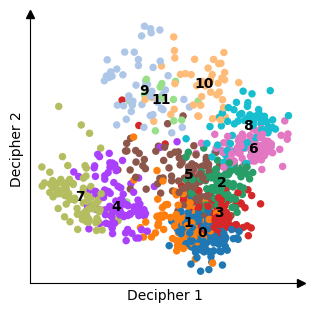

In [9]:
adata.uns.pop("diffmap_evals", None)
adata.obsm.pop("X_diffmap", None)

dc.tl.cell_clusters(adata)
dc.pl.decipher(adata, ["decipher_clusters"], legend_loc="on data");

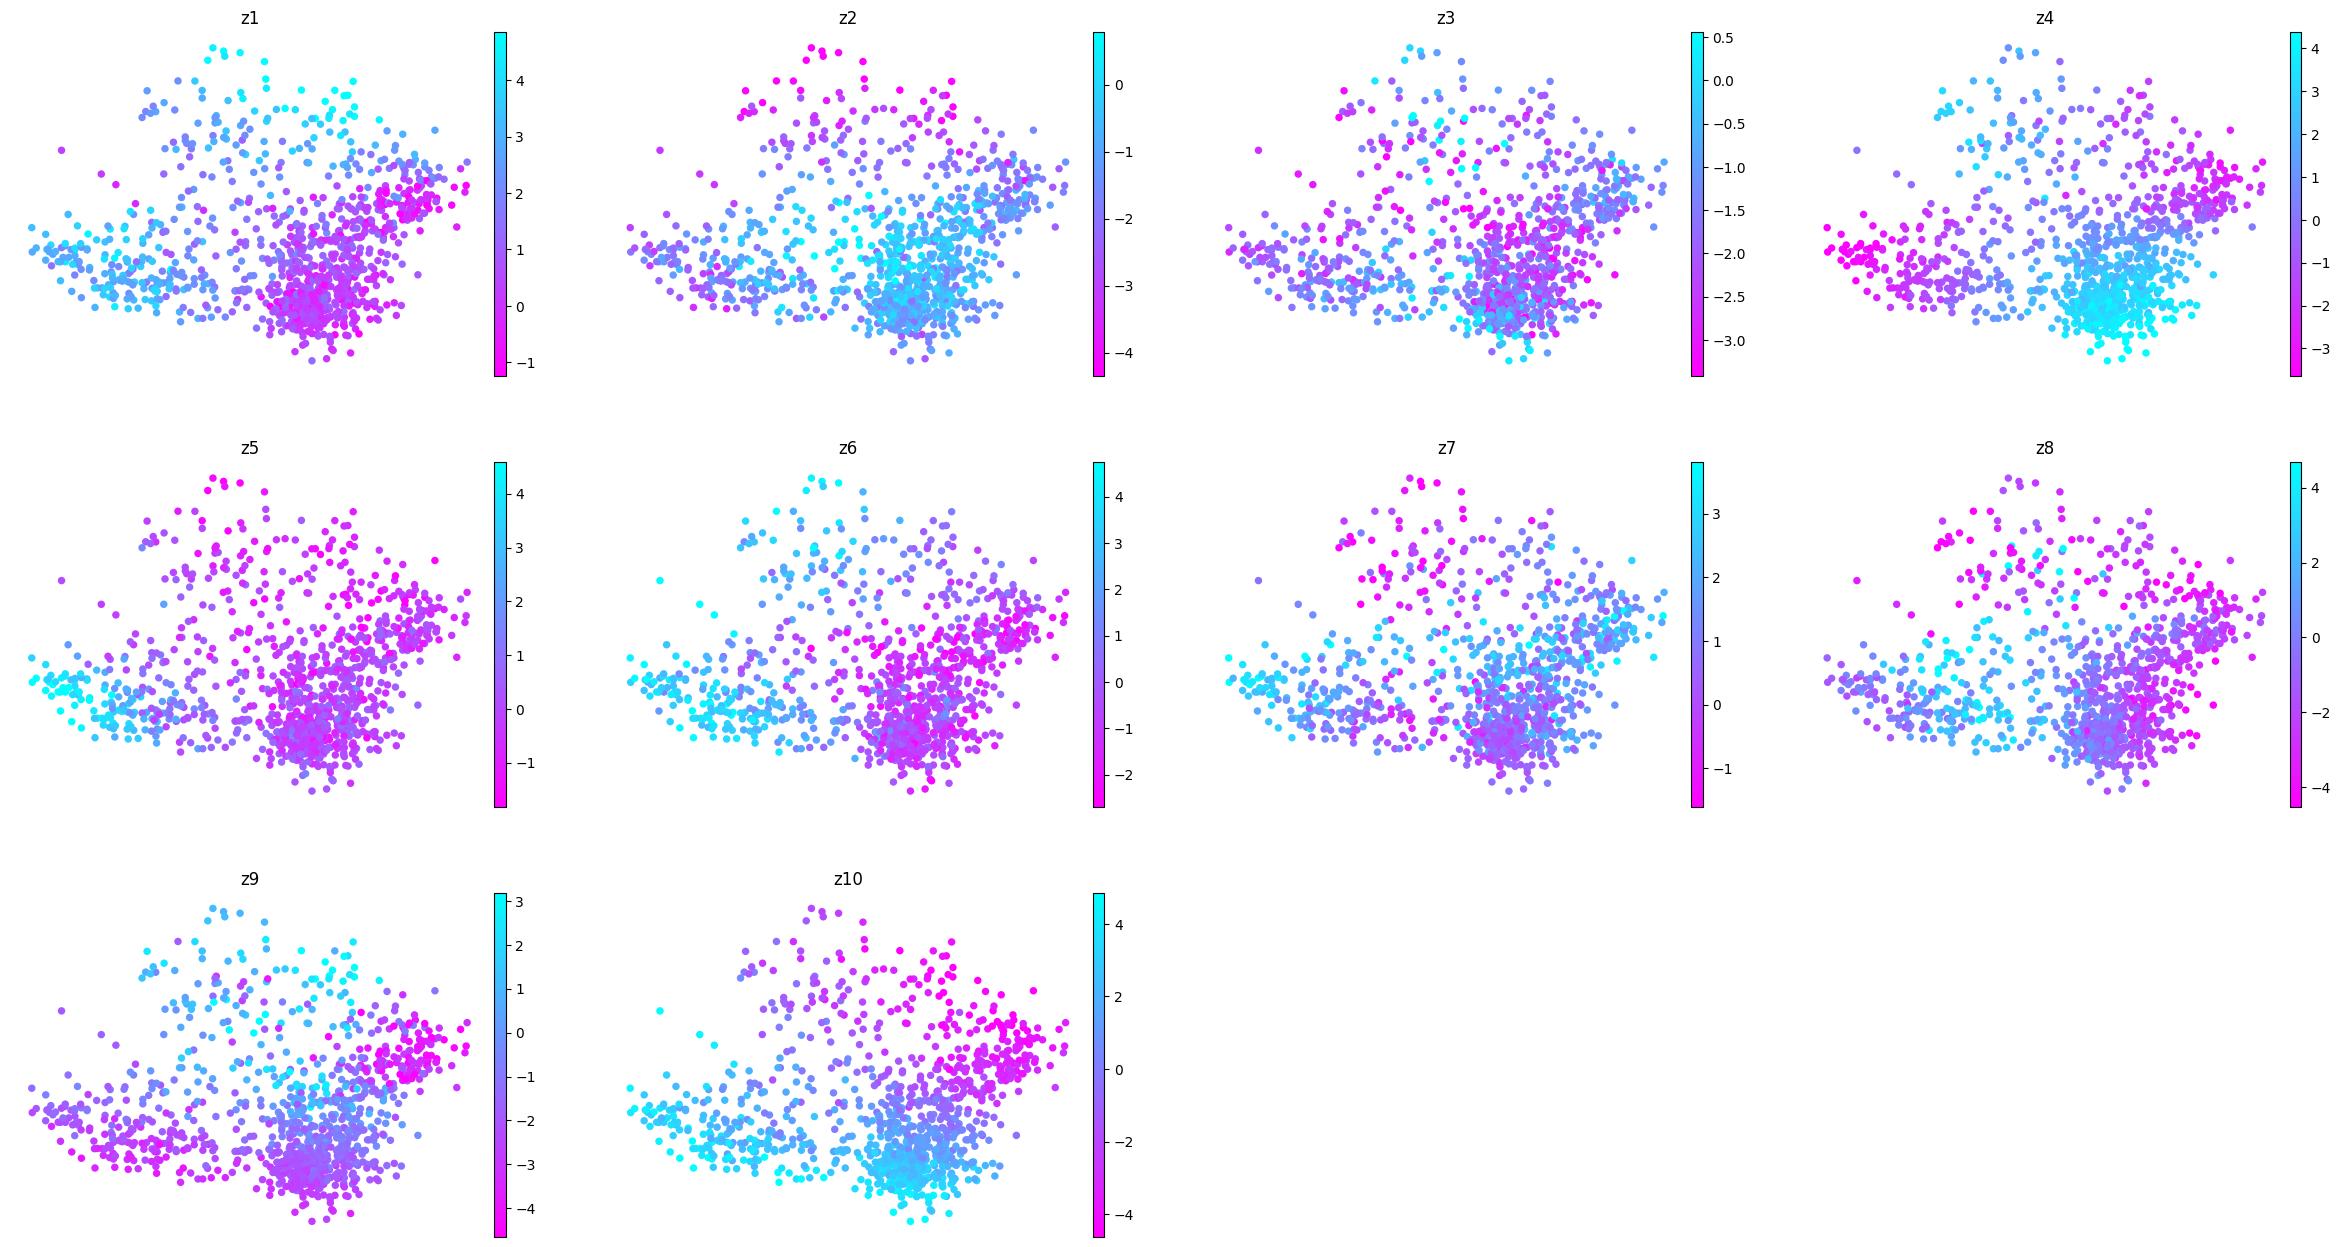

In [10]:
dc.pl.decipher_z(adata);

## Save outputs

In [12]:
adata.write("decipher_outputs3/decipher_run_full.h5ad")

np.savez(
    "decipher_outputs3/decipher_embeddings.npz",
    v=adata.obsm["decipher_v"],
    z=adata.obsm["decipher_z"]
)